# STN controls: orientation, untrained baseline, null model, ties, probes
Controls for the comparison in `stn_clusters.ipynb`. The edge distance ignores the direction of a tour, while the LSTM encoder reads a sequence, so a tour and its reversal can land far apart in the embedding. That competes with the reading that the embedding encodes run identity.

- (a) embedding distance of a tour to its own reversal vs. distances between close tours;
- (b) the STN comparison repeated with every tour (centers and all elites) in canonical orientation (`perm[0] < perm[-1]`), and the same pipeline for the untrained encoder (the initialization training starts from);
- a null model for best-strength, random tie-breaking, and linear probes for run identity and generation.

All logic lives in `dl_permutations.stn_controls`; the cached trajectories and encoder in `outputs/` are reused.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir("..")

In [2]:
import numpy as np
import torch
from dl_permutations import stn_clusters as S
from dl_permutations import stn_controls as K

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data, model, Z = S.load_inputs(device)
val_runs, _ = S.split_runs()
untrained = K.random_init_encoder(device)
perms = data["perm"]
reversed_perms, canonical = K.reverse_tours(perms), K.canonical_orientation(perms)
variants = {
    "trained": Z,
    "trained, canonical": K.unit_embeddings(model, canonical, device),
    "random init": K.unit_embeddings(untrained, perms, device),
    "random init, canonical": K.unit_embeddings(untrained, canonical, device),
}
print(f"{len(perms)} elites, {len(np.unique(data['run_id']))} runs, "
      f"{np.mean(perms[:, 0] < perms[:, -1]):.0%} already in canonical orientation")

1854 elites, 100 runs, 38% already in canonical orientation


## (a) Distance to the own reversal
Embedding distances between unit vectors (0 to 2). `own reversal`: every elite against the same cycle traversed backwards (edge distance 0). `same cycle stored reversed`: pairs of elites in the data that are the same cycle in opposite orientations. `consecutive elites of a run`: the positive pairs of training. `edge distance 1-4`: distinct tours that are close in permutation space. Below each table: the best tour's distance to its reversal, the median distance from the best tour to its close tours (edge distance <= 4), and the share of distinct tours lying closer to a tour than its own reversal (best tour, median over elites).

In [3]:
for name, encoder in (("trained", model), ("random init", untrained)):
    rows, summary = K.reversal_report(variants[name], K.unit_embeddings(encoder, reversed_perms, device), data)
    print(name)
    print(S.format_table(rows, ["pairs", "n", "edge_median", "emb_q25", "emb_median", "emb_q75"]))
    print("\n".join(f"  {key}: {value:.3f}" for key, value in summary.items()), end="\n\n")

trained
                      pairs       n edge_median emb_q25 emb_median emb_q75
               own reversal    1854       0.000   1.530      1.632   1.710
 same cycle stored reversed       2       0.000   1.706      1.706   1.706
consecutive elites of a run    1754       6.000   0.154      0.384   0.643
          edge distance 1-4    1492       4.000   0.082      0.216   0.648
         all distinct pairs 1717727      14.000   1.221      1.417   1.566
  best_to_reversal: 1.671
  best_close_tours: 19.000
  best_to_close_median: 1.213
  best_closer_than_reversal: 0.906
  median_closer_than_reversal: 0.852



random init
                      pairs       n edge_median emb_q25 emb_median emb_q75
               own reversal    1854       0.000   0.355      0.399   0.445
 same cycle stored reversed       2       0.000   0.368      0.368   0.368
consecutive elites of a run    1754       6.000   0.008      0.072   0.211
          edge distance 1-4    1492       4.000   0.002      0.020   0.117
         all distinct pairs 1717727      14.000   0.268      0.337   0.401
  best_to_reversal: 0.305
  best_close_tours: 19.000
  best_to_close_median: 0.100
  best_closer_than_reversal: 0.647
  median_closer_than_reversal: 0.764



## (b) Canonical orientation and the untrained baseline
Same centers and permutation-space labels as in `stn_clusters.ipynb`; only the embedding changes. `canonical`: centers and all elites embedded in canonical orientation, so both orientations of a cycle get the same vector. `random init`: the untrained encoder. AMI is shown next to ARI (both corrected for chance); `*_val`: validation runs only, `*_km`: k-means in the embedding instead of the shared centers. `n_end_emb`, `best_strength_emb`: STN metrics in the embedding variant; the permutation-space values are in the null-model table below.

In [4]:
rows, results = K.compare_variants(data, variants, val_runs, S.STN_N_CENTERS)
print(S.format_table(rows, ["variant", "k", "ari", "ami", "ari_val", "ami_val", "ari_km", "ami_km",
                            "seq_sim", "end_equal", "n_end_emb", "best_strength_emb"]))

               variant  k   ari   ami ari_val ami_val ari_km ami_km seq_sim end_equal n_end_emb best_strength_emb
               trained  5 0.013 0.008   0.028   0.033  0.002  0.004   0.257     0.220         5             0.620
               trained 10 0.011 0.015   0.039   0.047  0.011  0.024   0.174     0.130        10             0.410
               trained 20 0.020 0.047   0.070   0.128  0.019  0.054   0.133     0.140        19             0.280
               trained 50 0.034 0.123   0.110   0.229  0.039  0.141   0.123     0.160        36             0.100
    trained, canonical  5 0.001 0.002   0.012   0.016  0.002  0.005   0.331     0.190         5             0.670
    trained, canonical 10 0.010 0.013   0.031   0.061  0.007  0.011   0.208     0.110        10             0.540
    trained, canonical 20 0.015 0.030   0.026   0.069  0.018  0.040   0.137     0.130        19             0.470
    trained, canonical 50 0.030 0.101   0.092   0.188  0.032  0.114   0.134     0.150   

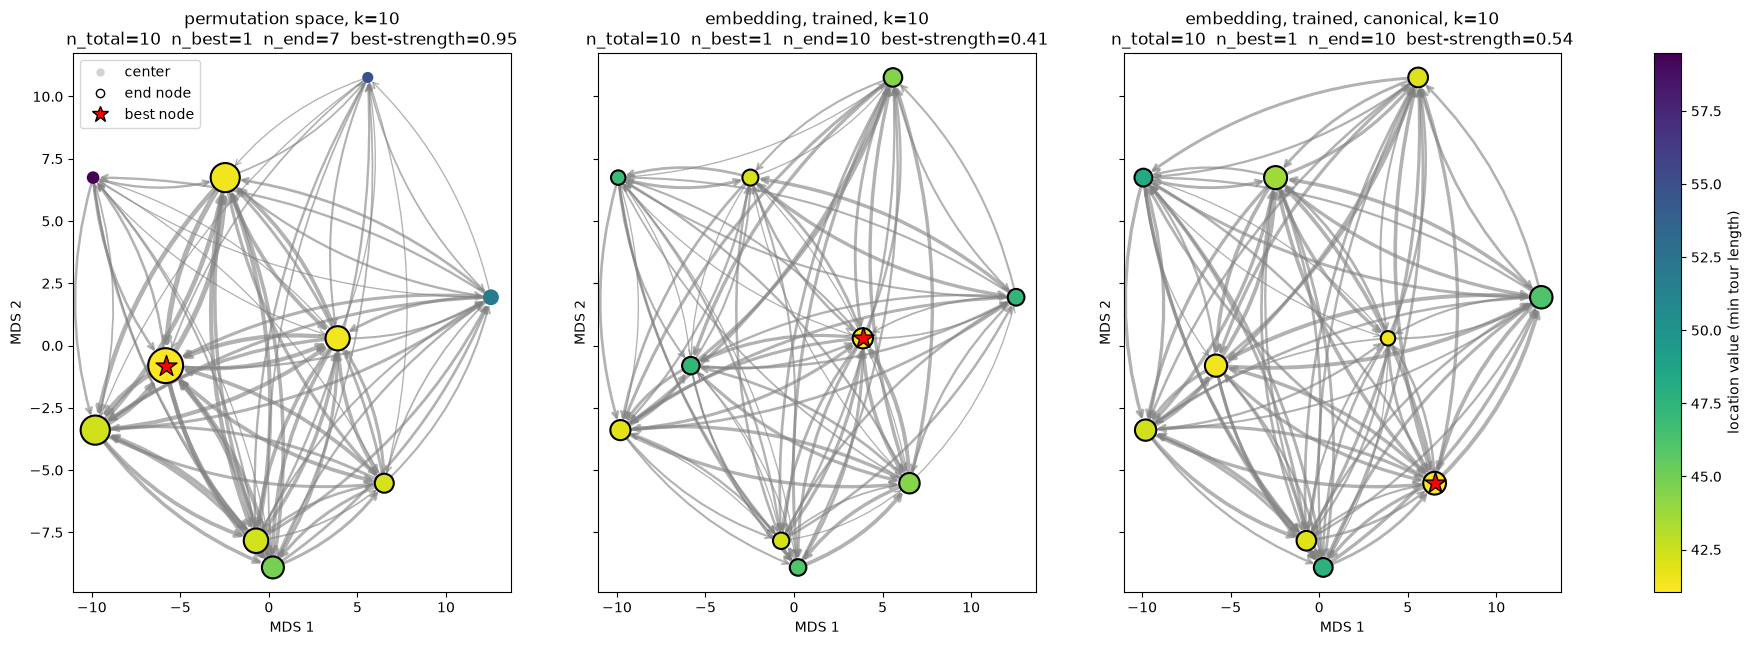

In [5]:
res = results["trained", 10]
S.plot_stns((res["G_perm"], res["G_emb"], results["trained, canonical", 10]["G_emb"]),
            ("permutation space, k=10", "embedding, trained, k=10", "embedding, trained, canonical, k=10"),
            res["pos"]);

## Null model for best-strength
Labels shuffled across all elites (1000 permutations), which keeps the size of every cell; the best node stays the cell of the best tour, so its size (`best_share`, share of elites) is kept too. `percentile`: position of the observed value in the null distribution (0 = below every shuffle, 1 = above every shuffle). The shuffle also removes the temporal autocorrelation of runs: `moves_per_run` vs `moves_per_run_null` shows how many more location changes shuffled runs make, which by itself raises the chance of entering any cell.

In [6]:
spaces = {"perm": ("trained", "perm_labels"), **{f"emb: {v}": (v, "emb_labels") for v in variants}}
print(S.format_table(K.null_rows(results, spaces, data),
                     ["k", "space", "best_share", "observed", "null_mean", "null_q025", "null_q975",
                      "percentile", "moves_per_run", "moves_per_run_null"]))

 k                       space best_share observed null_mean null_q025 null_q975 percentile moves_per_run moves_per_run_null
 5                        perm      0.410    0.970     0.999     0.990     1.000      0.000         8.370             12.634
 5                emb: trained      0.277    0.620     0.992     0.970     1.000      0.000         3.840             13.701
 5     emb: trained, canonical      0.230    0.670     0.982     0.950     1.000      0.000         6.010             13.938
 5            emb: random init      0.543    0.660     0.999     0.990     1.000      0.000         3.670             11.404
 5 emb: random init, canonical      0.305    0.790     0.995     0.980     1.000      0.000         5.180             12.518
10                        perm      0.307    0.950     0.995     0.980     1.000      0.000        10.300             14.500
10                emb: trained      0.121    0.410     0.882     0.830     0.930      0.000         4.980             15.442


## Ties: random tie-breaking
Elites at equal edge distance to several centers go to a random tied center (10 seeds, the same choice for all copies of a cycle) instead of the lowest index. `ties`: share of tied elites, `relabeled`: mean share of elites whose location changes. Metrics as lowest-index value [min, max over seeds]; ARI / AMI against the embedding partition of the trained encoder.

In [7]:
spreads = [K.tie_spread(data, Z, k) for k in S.STN_N_CENTERS]
print(S.format_table(K.tie_rows(spreads), ["k", "ties", "relabeled", "ari", "ami", "n_end", "best_strength"]))

 k  ties relabeled                  ari                  ami       n_end        best_strength
 5 0.266     0.146 0.013 [0.008, 0.013] 0.008 [0.007, 0.012]    4 [4, 4] 0.970 [0.960, 0.990]
10 0.344     0.199 0.011 [0.009, 0.014] 0.015 [0.011, 0.015]    7 [7, 7] 0.950 [0.870, 0.950]
20 0.368     0.212 0.020 [0.018, 0.021] 0.047 [0.038, 0.045] 11 [10, 12] 0.820 [0.690, 0.740]
50 0.385     0.233 0.034 [0.032, 0.036] 0.123 [0.115, 0.126] 23 [19, 24] 0.440 [0.290, 0.640]


## Linear probes: run identity and generation
Logistic regression for `run_id` (5 stratified folds within runs, so every run is seen in training; chance is the `none` row) and ridge regression for the generation (5 folds grouped by run, so it is tested on unseen runs). Features are standardized. `edge incidence` is the permutation-space representation (no orientation); `+ orientation` adds the bit `perm[0] < perm[-1]`.

In [8]:
features = {
    "none (chance)": np.zeros((len(perms), 1)),
    "tour length": data["fitness"][:, None],
    "edge incidence": S.edge_matrix(perms),
    "edge incidence + orientation": np.c_[S.edge_matrix(perms), perms[:, 0] < perms[:, -1]],
    **{f"embedding: {name}": Zv for name, Zv in variants.items()},
}
print(S.format_table(K.probe_rows(features, data), ["features", "dims", "run_acc", "gen_r2"]))

                         features dims run_acc gen_r2
                    none (chance)    1   0.016 -0.001
                      tour length    1   0.018  0.604
                   edge incidence  190   0.684  0.549
     edge incidence + orientation  191   0.693  0.549
               embedding: trained   64   0.695 -0.046
    embedding: trained, canonical   64   0.528  0.071
           embedding: random init   64   0.535 -0.031
embedding: random init, canonical   64   0.426  0.034
